# Model notebook template (CSCI167 Rotten Tomatoes project)

Make **your own copy** of this notebook for your architecture (File > Save a copy in Drive, or copy the file
in the repo, e.g. `notebooks/<yourname>_<model>.ipynb`).

Everything in here is **shared code that all of us use**: setup, data and splits, the common training settings,
the run function, the results table, learning curves and error analysis. Do not edit `common.py` or the shared
settings, so that all models are trained and evaluated the same way and the results are comparable.
The only part you write is the architecture, in the cell(s) under **YOUR ARCHITECTURE**.

Colab: Runtime > Change runtime type > GPU (T4), then run cells top to bottom.

In [1]:
%pip install -q datasets transformers
import os
if not os.path.exists("common.py"):
    REPO_URL = "https://github.com/ZhongVang/csci167-rotten-tomatoes.git"   # group repo (private until submission)
    !git clone $REPO_URL project
    %cd project

fatal: destination path 'project' already exists and is not an empty directory.
/content/project


In [2]:
# Optional (Colab): keep results on Drive so they survive session timeouts.
# Must run BEFORE `import common`.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.environ["RESULTS_DIR"] = "/content/drive/MyDrive/CSCI167_results"
except Exception:
    pass  # running locally: results go to ./results

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
OWNER = "Jaime"                   # TODO: your name; results go to results_<OWNER>.csv
RESULTS_FILE = f"results_{OWNER}.csv"
SEEDS = [0, 1, 2]                    # shared: do not change

import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from common import *

print(save_env_info(OWNER))          # package versions + hardware, for the report
data = load_data()
print({k: len(v[0]) for k, v in data.items()}, "-> train/val/test sizes")
print("label counts (train):", np.bincount(data["train"][1]))
print("example:", data["train"][0][0], "->", data["train"][1][0])

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'numpy': '2.4.6', 'cuda': '13.0', 'gpu': 'Tesla T4', 'common_version': '65ca4193', 'datasets': '4.8.5', 'transformers': '5.22.1', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'dataset_revision': 'aa13bc287fa6fcab6daf52f0dfb9994269ffea28', 'dataset_id': 'cornell-movie-review-data/rotten_tomatoes'}


{'train': 8530, 'validation': 1066, 'test': 1066} -> train/val/test sizes
label counts (train): [4265 4265]
example: the rock is destined to be the 21st century's new " conan " and that he's going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal . -> 1


## Shared training settings (do not change for the main runs)

Every model in the group is trained with the same budget so the comparison is fair: Adam, lr 1e-3, batch 64,
at most 20 epochs, early stopping (patience 5) on **validation** accuracy; the best-validation weights are
restored and the test set is evaluated once at the end. The same 3 seeds are used for 100%, 25% and 10% of the
training data. Data: official splits of `cornell-movie-review-data/rotten_tomatoes`
(train 8,530 / validation 1,066 / test 1,066).

In [4]:
TAG = "mlp"               # TODO: short unique name used in run names / files (e.g. "cnn")
MODEL_NAME = "Multilayer perceptron"       # TODO: descriptive name shown in the results table

PROTOCOL = dict(optimizer="adam", lr=1e-3, batch_size=64, epochs=20, patience=5)
FRACS = [1.0, 0.25, 0.1]

def run(seed, frac, tag=None, **overrides):
    """Train + evaluate one run and log it to results/<RESULTS_FILE>.
    overrides: training settings (optimizer, lr, weight_decay, schedule, momentum) go to the trainer;
    anything else is passed to MyModel(...) as a model hyperparameter (e.g. dropout=0.0)."""
    train_keys = {"optimizer", "lr", "weight_decay", "schedule", "momentum"}
    tcfg = {**PROTOCOL, **{k: v for k, v in overrides.items() if k in train_keys}}
    mcfg = {k: v for k, v in overrides.items() if k not in train_keys}
    set_seed(seed)                                    # BEFORE building the model
    train_dl, val_dl, test_dl, vocab = make_vocab_loaders(data, tcfg["batch_size"], seed, train_frac=frac)
    model = MyModel(len(vocab), **mcfg)
    return train_and_eval(model, (train_dl, val_dl, test_dl), run_name=f"{tag or TAG}_f{frac}_s{seed}",
                          model_name=MODEL_NAME, seed=seed, train_frac=frac, extra=mcfg,
                          results_file=RESULTS_FILE, **tcfg)

## YOUR ARCHITECTURE

The architectures have not been chosen yet. Add your own code cell(s) below this one and define your model there.
You can build any deep learning architecture suited to text classification, as long as it is different from the
other group members' models. Some starting points (not a requirement): a fully connected network on pooled word
embeddings, a 1D CNN, an RNN/LSTM, a transformer, or a pretrained model (`HFClassifier` in `common.py` wraps a
Hugging Face model, fine-tuned or with a frozen encoder). The course textbook (Understanding Deep Learning)
covers fully connected networks (Ch 3-4), convolutional networks (Ch 10), residual networks (Ch 11) and
transformers (Ch 12).

**What the shared code expects:** a class named `MyModel(nn.Module)` with

- `__init__(self, vocab_size, **your_hyperparameters)`: every extra argument needs a default value, so
  `MyModel(vocab_size)` works. Index 0 is the padding token.
- `forward(self, ids, mask)`: `ids` is a LongTensor `[batch, length]` of token indices, `mask` is a BoolTensor
  `[batch, length]` that is True for real tokens and False for padding. It must return logits of shape
  `[batch, 2]` (class 0 = negative, 1 = positive).

(Pretrained Hugging Face models use their own tokenizer, so they need `make_hf_loaders` and a separate run
function. Ask the group before choosing one, so the comparison stays consistent.)

**Write down for the report:** why you chose this architecture, its structure and trainable parameter count
(printed below), how its depth and layer choices might affect learning, and what is trained or frozen if you
use a pretrained model or library code (cite the source).

**Hyperparameter study (the rubric requires one; the group decides who runs it):** investigate at least two
training factors with at least two settings each, changing one factor at a time versus a reference config, and
choose settings using validation accuracy only. Possible factors: optimizer, learning rate, batch size,
lr schedule, regularization (dropout, weight decay), augmentation. You can run each setting with the shared
function, for example `run(seed, 1.0, tag=TAG + "_sgd", optimizer="sgd", lr=0.05)` for each seed in `SEEDS`,
and compare them in the summary table below (convergence speed, validation accuracy, stability, training time).

In [5]:
class MyModel(nn.Module):

  def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, dropout=0.3):
    super().__init__()

    self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

    self.fc1 = nn.Linear(embed_dim, hidden_dim)
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(dropout)
    self.fc2 = nn.Linear(hidden_dim, 2)

  def forward(self, ids, mask):
      #converts token IDs into word embeddings
      x = self.embedding(ids)
      #ignore padding tokens
      mask = mask.unsqueeze(-1).float()
      x = x * mask

      #average the word embeddings
      x = x.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
      #hidden layers
      x = self.fc1(x)
      x = self.relu(x)
      x = self.dropout(x)
      #output layers
      x = self.fc2(x)
      return x

## Sanity check (run once your model is defined)

Builds your model, prints its structure and trainable parameter count (needed for the report), and checks
the output shape on a real batch. Then run one short test (10% of the data) before the full runs.

In [6]:
set_seed(0)
train_dl, val_dl, test_dl, vocab = make_vocab_loaders(data, 64, 0)
model = MyModel(len(vocab))
print(model)
print("trainable / total params:", count_params(model))
inputs, y = next(iter(train_dl))
out = model(**inputs)
assert out.shape == (len(y), 2), f"forward() must return logits of shape [batch, 2], got {tuple(out.shape)}"
print("OK: logits", tuple(out.shape), "| ids", tuple(inputs['ids'].shape))

MyModel(
  (embedding): Embedding(8981, 128, padding_idx=0)
  (fc1): Linear(in_features=128, out_features=128, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)
trainable / total params: (1166338, 1166338)
OK: logits (64, 2) | ids (64, 46)


In [7]:
run(0, 0.1, tag=TAG + '_test')   # quick test: if validation accuracy is above 50%, launch the full runs

[mlp_test_f0.1_s0] ep 01 train_loss 0.6990 train_acc 0.4707 val_loss 0.6931 val_acc 0.5056
[mlp_test_f0.1_s0] ep 02 train_loss 0.6779 train_acc 0.6209 val_loss 0.6888 val_acc 0.5432
[mlp_test_f0.1_s0] ep 03 train_loss 0.6663 train_acc 0.6549 val_loss 0.6839 val_acc 0.5835
[mlp_test_f0.1_s0] ep 04 train_loss 0.6487 train_acc 0.6913 val_loss 0.6795 val_acc 0.5835
[mlp_test_f0.1_s0] ep 05 train_loss 0.6321 train_acc 0.6784 val_loss 0.6779 val_acc 0.5779
[mlp_test_f0.1_s0] ep 06 train_loss 0.6071 train_acc 0.7113 val_loss 0.6761 val_acc 0.5788
[mlp_test_f0.1_s0] ep 07 train_loss 0.5793 train_acc 0.7207 val_loss 0.6818 val_acc 0.5872
[mlp_test_f0.1_s0] ep 08 train_loss 0.5464 train_acc 0.7488 val_loss 0.6824 val_acc 0.5919
[mlp_test_f0.1_s0] ep 09 train_loss 0.5126 train_acc 0.7782 val_loss 0.6989 val_acc 0.5807
[mlp_test_f0.1_s0] ep 10 train_loss 0.4877 train_acc 0.7758 val_loss 0.6897 val_acc 0.6023
[mlp_test_f0.1_s0] ep 11 train_loss 0.4446 train_acc 0.8181 val_loss 0.6936 val_acc 0.6107

{'timestamp': '2026-11-27T00:47:42',
 'run_name': 'mlp_test_f0.1_s0',
 'model': 'Multilayer perceptron',
 'seed': 0,
 'train_frac': 0.1,
 'n_train': 852,
 'n_val': 1066,
 'n_test': 1066,
 'optimizer': 'adam',
 'lr': 0.001,
 'weight_decay': 0.0,
 'schedule': 'constant',
 'batch_size': 64,
 'epochs_max': 20,
 'patience': 5,
 'epochs_run': 16,
 'best_epoch': 11,
 'best_val_acc': 0.6107,
 'test_acc': 0.6248,
 'test_f1': 0.6236,
 'trainable_params': 208642,
 'total_params': 208642,
 'train_seconds': 1.5,
 'device': 'cuda',
 'common_version': '65ca4193',
 'extra': '{}'}

## Main runs: 3 seeds x 100% / 25% / 10% of the training data

In [8]:
for frac in FRACS:
    for seed in SEEDS:
        run(seed, frac)

[mlp_f1.0_s0] ep 01 train_loss 0.6752 train_acc 0.5762 val_loss 0.6626 val_acc 0.6060
[mlp_f1.0_s0] ep 02 train_loss 0.6086 train_acc 0.6756 val_loss 0.6166 val_acc 0.6585
[mlp_f1.0_s0] ep 03 train_loss 0.5138 train_acc 0.7483 val_loss 0.5830 val_acc 0.6951
[mlp_f1.0_s0] ep 04 train_loss 0.4235 train_acc 0.8025 val_loss 0.5790 val_acc 0.7120
[mlp_f1.0_s0] ep 05 train_loss 0.3469 train_acc 0.8508 val_loss 0.6041 val_acc 0.7205
[mlp_f1.0_s0] ep 06 train_loss 0.2840 train_acc 0.8818 val_loss 0.6100 val_acc 0.7251
[mlp_f1.0_s0] ep 07 train_loss 0.2311 train_acc 0.9074 val_loss 0.6567 val_acc 0.7167
[mlp_f1.0_s0] ep 08 train_loss 0.1877 train_acc 0.9279 val_loss 0.7066 val_acc 0.7120
[mlp_f1.0_s0] ep 09 train_loss 0.1487 train_acc 0.9451 val_loss 0.7807 val_acc 0.7158
[mlp_f1.0_s0] ep 10 train_loss 0.1169 train_acc 0.9606 val_loss 0.8797 val_acc 0.7167
[mlp_f1.0_s0] ep 11 train_loss 0.0943 train_acc 0.9691 val_loss 0.9538 val_acc 0.7111
[mlp_f1.0_s0] early stop at epoch 11
[mlp_f1.0_s0] bes

## Results: summary table, learning curves, error analysis

In [9]:
summarize(f'results_{OWNER}.csv')   # mean +/- std over seeds, per configuration

,model,train_frac,optimizer,lr,weight_decay,schedule,batch_size,extra,n_seeds,val_acc,val_std,test_acc,test_std,test_f1,params,seconds
0,Multilayer perceptron,0.10,adam,0.001,0.0,constant,64,{},3,0.6191,0.0102,0.6264,0.0032,0.6258,208642,1.5000
1,Multilayer perceptron,0.25,adam,0.001,0.0,constant,64,{},3,0.6648,0.0028,0.6707,0.0062,0.6702,445058,2.5667
2,Multilayer perceptron,1.00,adam,0.001,0.0,constant,64,{},3,0.7373,0.0118,0.7455,0.0174,0.7454,1166338,5.4333


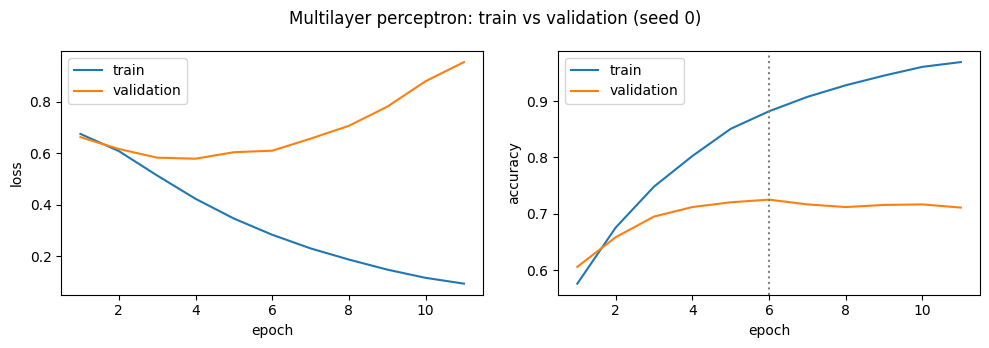

In [10]:
plot_history(f"{TAG}_f1.0_s0", f"{MODEL_NAME}: train vs validation (seed 0)");

In [11]:
import json
h = json.load(open(f"{RESULTS_DIR}/history/{TAG}_f1.0_s0.json"))
preds, labels = np.array(h["test_preds"]), np.array(data["test"][1])
texts = data["test"][0]
cm = np.zeros((2, 2), int)
for y, p in zip(labels, preds): cm[y, p] += 1
print("confusion matrix (rows=true neg/pos, cols=pred neg/pos):\n", cm)
wrong = np.where(preds != labels)[0]
print(len(wrong), "errors. Examples (true, pred, text):")
for i in wrong[:20]: print(labels[i], preds[i], "|", texts[i])

confusion matrix (rows=true neg/pos, cols=pred neg/pos):
 [[425 108]
 [144 389]]
252 errors. Examples (true, pred, text):
1 0 | weighty and ponderous but every bit as filling as the treat of the title .
1 0 | a real audience-pleaser that will strike a chord with anyone who's ever waited in a doctor's office , emergency room , hospital bed or insurance company office .
1 0 | generates an enormous feeling of empathy for its characters .
1 0 | exposing the ways we fool ourselves is one hour photo's real strength .
1 0 | mostly , [goldbacher] just lets her complicated characters be unruly , confusing and , through it all , human .
1 0 | this is a fascinating film because there is no clear-cut hero and no all-out villain .
1 0 | devotees of star trek ii : the wrath of khan will feel a nagging sense of deja vu , and the grandeur of the best next generation episodes is lacking .
1 0 | what's so striking about jolie's performance is that she never lets her character become a caricature -- not 

## Notes for the report (fill in)

- **Design choices:** why this architecture, why these sizes/layers? What did you expect it to do well or badly?
- **Learning curves:** does it overfit (train accuracy far above validation)? When does validation peak?
- **Errors:** what do the misclassified sentences have in common (negation, sarcasm, mixed opinions, very short text)?
- **Less data:** how much does accuracy drop at 25% and 10%?
- **Limitations:** 3 seeds, small test set (about 1,066 sentences), anything you would do differently.